<a href="https://colab.research.google.com/github/MilagrosBrucellaria/preentrega-10-clasificacion-churn-/blob/main/PreEntrega10_ModeladoyEvaluaci%C3%B3nDeClasificaci%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pre-Entrega 10 - Modelado y Evaluación de Clasificación

## Predicción de abandono de clientes (Customer Churn)

### Objetivo

El objetivo de este proyecto es desarrollar un modelo de clasificación binaria que permita predecir si un cliente abandonará o no un servicio de telecomunicaciones.

Para realizar el análisis se utilizará el dataset **Telco Customer Churn**, que contiene información sobre las características de los clientes, los servicios contratados, su permanencia, modalidad de contrato y cargos asociados.

La variable objetivo del problema es **Churn**, que presenta dos posibles valores:

- **Yes:** el cliente abandonó el servicio.
- **No:** el cliente permaneció en el servicio.

El desarrollo incluirá las siguientes etapas:

1. Carga y exploración inicial de los datos.
2. Preparación de las variables.
3. División de los datos en conjuntos de entrenamiento y prueba (80/20).
4. Entrenamiento de un modelo de clasificación mediante **Logistic Regression**.
5. Generación de predicciones sobre el conjunto de prueba.
6. Evaluación mediante Accuracy, Precision, Recall y F1-Score.
7. Análisis de la matriz de confusión.
8. Interpretación de los resultados desde la perspectiva del negocio.

En problemas de **Customer Churn**, resulta especialmente importante identificar correctamente a los clientes que realmente abandonarán el servicio. Por este motivo, además del desempeño general del modelo, se analizará especialmente el **Recall** y el impacto de los **falsos negativos**.

In [1]:
# Manipulación y análisis de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# División de datos
from sklearn.model_selection import train_test_split

# Preprocesamiento
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Modelo de clasificación
from sklearn.linear_model import LogisticRegression

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [4]:
# Carga del dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset cargado correctamente.")
print(f"Cantidad de filas: {df.shape[0]}")
print(f"Cantidad de columnas: {df.shape[1]}")

Dataset cargado correctamente.
Cantidad de filas: 7043
Cantidad de columnas: 21


## Exploración inicial de los datos

La exploración inicial permite conocer la estructura del dataset antes de comenzar el modelado.

Se analizaron las dimensiones del conjunto de datos, los tipos de variables, la existencia de valores faltantes, la cantidad de valores únicos y la distribución de la variable objetivo **Churn**.

Este análisis es especialmente importante porque permite detectar variables que requieren tratamiento antes de entrenar el modelo. En particular, se verificará el formato de `TotalCharges`, ya que debe ser una variable numérica, y se eliminará `customerID` del conjunto de variables predictoras porque funciona únicamente como identificador del cliente.

También se analizó la distribución de la variable objetivo para determinar si existe un desbalance entre clientes que abandonaron el servicio (`Yes`) y aquellos que permanecieron (`No`). Este aspecto será relevante posteriormente para interpretar correctamente métricas como **Accuracy, Precision, Recall y F1-Score**.


In [7]:
# ============================================================
# EXPLORACIÓN INICIAL DEL DATASET
# ============================================================

# 1. Primeras filas
print("=== PRIMERAS FILAS DEL DATASET ===")
display(df.head())

# 2. Dimensiones
print("\n=== DIMENSIONES ===")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

# 3. Información general
print("\n=== INFORMACIÓN GENERAL ===")
df.info()

# 4. Valores nulos
print("\n=== VALORES NULOS ===")
print(df.isnull().sum())

# 5. Valores únicos por variable
print("\n=== CANTIDAD DE VALORES ÚNICOS ===")
print(df.nunique())

# 6. Distribución de la variable objetivo
print("\n=== DISTRIBUCIÓN DE CHURN ===")
print(df["Churn"].value_counts())

print("\n=== DISTRIBUCIÓN PORCENTUAL DE CHURN ===")
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

# 7. Estadísticas de variables numéricas
print("\n=== ESTADÍSTICAS DESCRIPTIVAS ===")
display(df.describe())

=== PRIMERAS FILAS DEL DATASET ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



=== DIMENSIONES ===
Filas: 7043
Columnas: 21

=== INFORMACIÓN GENERAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract      

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
# ============================================================
# PREPARACIÓN DE DATOS Y DIVISIÓN TRAIN / TEST
# ============================================================

# Creamos una copia del dataset original
df_modelo = df.copy()

# ------------------------------------------------------------
# 1. Convertir TotalCharges a variable numérica
# ------------------------------------------------------------

# Los valores que no puedan convertirse (por ejemplo espacios vacíos)
# se transformarán temporalmente en NaN
df_modelo["TotalCharges"] = pd.to_numeric(
    df_modelo["TotalCharges"],
    errors="coerce"
)

# Verificamos cuántos valores quedaron como NaN
nulos_totalcharges = df_modelo["TotalCharges"].isnull().sum()

print("=== LIMPIEZA DE TotalCharges ===")
print(f"Valores nulos luego de la conversión: {nulos_totalcharges}")

# Eliminamos los registros donde TotalCharges quedó vacío
df_modelo = df_modelo.dropna(subset=["TotalCharges"]).copy()

print(f"Registros disponibles luego de la limpieza: {len(df_modelo)}")
print(f"Tipo de TotalCharges: {df_modelo['TotalCharges'].dtype}")


# ------------------------------------------------------------
# 2. Eliminar customerID
# ------------------------------------------------------------

# customerID es únicamente un identificador y no aporta
# información predictiva al modelo
df_modelo = df_modelo.drop(columns=["customerID"])


# ------------------------------------------------------------
# 3. Transformar la variable objetivo Churn
# ------------------------------------------------------------

# No  = 0 → cliente que permanece
# Yes = 1 → cliente que abandona
df_modelo["Churn"] = df_modelo["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("\n=== VARIABLE OBJETIVO ===")
print(df_modelo["Churn"].value_counts())


# ------------------------------------------------------------
# 4. Separar variables predictoras y objetivo
# ------------------------------------------------------------

X = df_modelo.drop(columns=["Churn"])
y = df_modelo["Churn"]


# ------------------------------------------------------------
# 5. Identificar variables categóricas y numéricas
# ------------------------------------------------------------

variables_categoricas = X.select_dtypes(
    include=["object"]
).columns.tolist()

variables_numericas = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("\n=== VARIABLES DEL MODELO ===")
print(f"Variables predictoras totales: {X.shape[1]}")
print(f"Variables categóricas: {len(variables_categoricas)}")
print(f"Variables numéricas: {len(variables_numericas)}")

print("\nVariables numéricas:")
print(variables_numericas)


# ------------------------------------------------------------
# 6. División Train / Test 80-20
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ------------------------------------------------------------
# 7. Verificación final
# ------------------------------------------------------------

print("\n=== DIVISIÓN TRAIN / TEST ===")
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print("\n=== PROPORCIÓN DE CHURN ===")
print(f"Train: {y_train.mean() * 100:.2f}%")
print(f"Test:  {y_test.mean() * 100:.2f}%")

=== LIMPIEZA DE TotalCharges ===
Valores nulos luego de la conversión: 11
Registros disponibles luego de la limpieza: 7032
Tipo de TotalCharges: float64

=== VARIABLE OBJETIVO ===
Churn
0    5163
1    1869
Name: count, dtype: int64

=== VARIABLES DEL MODELO ===
Variables predictoras totales: 19
Variables categóricas: 15
Variables numéricas: 4

Variables numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

=== DIVISIÓN TRAIN / TEST ===
X_train: (5625, 19)
X_test:  (1407, 19)
y_train: (5625,)
y_test:  (1407,)

=== PROPORCIÓN DE CHURN ===
Train: 26.58%
Test:  26.58%


## Preparación de los datos y división Train/Test

Antes de entrenar el modelo se realizó una etapa de preparación de los datos para asegurar que las variables tuvieran un formato adecuado para el problema de clasificación.

En primer lugar, se detectó que la variable `TotalCharges`, que representa el importe total facturado al cliente, estaba almacenada como texto (`object`). Para utilizarla correctamente en el modelo fue convertida a formato numérico. Durante esta conversión se identificaron **11 registros con valores no convertibles**, los cuales fueron tratados como valores faltantes y eliminados. Como resultado, el dataset pasó de **7.043 a 7.032 registros**.

También se eliminó la variable `customerID`, ya que funciona únicamente como identificador único de cada cliente y no aporta información relevante para predecir el abandono del servicio.

La variable objetivo `Churn` fue transformada a formato binario:

- **0:** el cliente permanece en el servicio.
- **1:** el cliente abandona el servicio.

Luego se separaron las variables predictoras (`X`) de la variable objetivo (`y`). El conjunto quedó compuesto por **19 variables predictoras**, de las cuales **15 son categóricas y 4 numéricas**.

Finalmente, los datos fueron divididos en:

- **80 % para entrenamiento:** 5.625 registros.
- **20 % para prueba:** 1.407 registros.

La división se realizó utilizando `random_state=42` para garantizar la reproducibilidad del experimento y `stratify=y` para conservar la proporción de la variable objetivo en ambos conjuntos.

La proporción de clientes con Churn resultó de aproximadamente **26,58 % tanto en entrenamiento como en prueba**, confirmando que la división estratificada mantuvo correctamente la distribución de la clase objetivo.

In [9]:
# ============================================================
# PREPROCESAMIENTO Y ENTRENAMIENTO DEL MODELO
# ============================================================

# 1. Configuramos el preprocesamiento de las variables
# Las variables categóricas se convierten mediante OneHotEncoder
# Las variables numéricas se estandarizan mediante StandardScaler

preprocesador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ]
)


# 2. Creamos un Pipeline que integra:
# - Preprocesamiento
# - Modelo de Regresión Logística

modelo = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        (
            "clasificador",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)


# 3. Entrenamos el modelo utilizando el conjunto de entrenamiento

modelo.fit(X_train, y_train)


# 4. Realizamos predicciones sobre el conjunto de prueba

y_pred = modelo.predict(X_test)


# 5. Verificamos que el proceso se haya ejecutado correctamente

print("=== ENTRENAMIENTO DEL MODELO ===")
print("Modelo Logistic Regression entrenado correctamente.")

print(f"\nRegistros utilizados para entrenamiento: {len(X_train)}")
print(f"Registros utilizados para prueba: {len(X_test)}")
print(f"Predicciones generadas: {len(y_pred)}")


# 6. Comparamos algunas predicciones con los valores reales

comparacion = pd.DataFrame({
    "Valor_real": y_test.iloc[:10].values,
    "Prediccion": y_pred[:10]
})

print("\n=== EJEMPLO DE PREDICCIONES ===")
display(comparacion)

=== ENTRENAMIENTO DEL MODELO ===
Modelo Logistic Regression entrenado correctamente.

Registros utilizados para entrenamiento: 5625
Registros utilizados para prueba: 1407
Predicciones generadas: 1407

=== EJEMPLO DE PREDICCIONES ===


,Valor_real,Prediccion
0,0,0
1,0,1
2,0,0
3,1,0
4,0,0
5,1,0
6,0,0
7,0,0
8,1,1
9,0,0


## Evaluación del modelo

Una vez entrenado el modelo de Regresión Logística, se evaluará su desempeño utilizando el conjunto de prueba.

Para obtener una visión completa del comportamiento del modelo se calcularán las siguientes métricas:

- **Accuracy:** proporción total de predicciones correctas.
- **Precision:** indica qué proporción de los clientes identificados como Churn realmente abandonaron el servicio.
- **Recall:** indica qué proporción de los clientes que realmente abandonaron el servicio fueron detectados correctamente por el modelo.
- **F1-Score:** combina Precision y Recall en una única métrica, permitiendo evaluar el equilibrio entre ambas.

Además, se utilizará una **matriz de confusión** para analizar los aciertos y errores del modelo, prestando especial atención a los falsos negativos: clientes que realmente abandonaron el servicio pero que el modelo clasificó como clientes que permanecerían.

En un problema de Churn, estos falsos negativos son especialmente relevantes desde el punto de vista del negocio, ya que representan clientes en riesgo que podrían no recibir una acción preventiva de retención.

=== MÉTRICAS DEL MODELO ===
Accuracy : 0.8038 (80.38%)
Precision: 0.6485 (64.85%)
Recall   : 0.5722 (57.22%)
F1-Score : 0.6080 (60.80%)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

=== MATRIZ DE CONFUSIÓN ===
[[917 116]
 [160 214]]

Detalle:
Verdaderos Negativos (TN): 917
Falsos Positivos (FP):     116
Falsos Negativos (FN):     160
Verdaderos Positivos (TP): 214


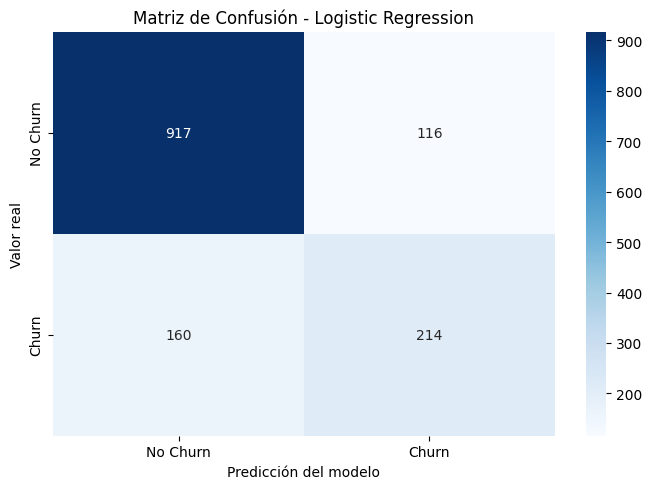

In [10]:
# ============================================================
# EVALUACIÓN DEL MODELO
# ============================================================

# 1. Calculamos las métricas principales
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# 2. Mostramos los resultados
print("=== MÉTRICAS DEL MODELO ===")
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-Score : {f1:.4f} ({f1 * 100:.2f}%)")


# 3. Reporte completo de clasificación
print("\n=== CLASSIFICATION REPORT ===")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)


# 4. Calculamos la matriz de confusión
matriz = confusion_matrix(y_test, y_pred)

tn, fp, fn, tp = matriz.ravel()

print("=== MATRIZ DE CONFUSIÓN ===")
print(matriz)

print("\nDetalle:")
print(f"Verdaderos Negativos (TN): {tn}")
print(f"Falsos Positivos (FP):     {fp}")
print(f"Falsos Negativos (FN):     {fn}")
print(f"Verdaderos Positivos (TP): {tp}")


# 5. Visualizamos la matriz de confusión
plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Matriz de Confusión - Logistic Regression")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")

plt.tight_layout()
plt.show()

## Interpretación de las métricas y conclusión

El modelo de Regresión Logística alcanzó un **Accuracy de 80,38 %**, lo que indica que clasificó correctamente aproximadamente 8 de cada 10 clientes del conjunto de prueba. Sin embargo, debido al desbalance existente en la variable objetivo, el Accuracy no debe analizarse de manera aislada.

Para la clase correspondiente a Churn, el modelo obtuvo una **Precision de 64,85 %**. Esto significa que, entre los clientes identificados por el modelo como posibles abandonos, aproximadamente el 65 % efectivamente abandonó el servicio.

El **Recall fue de 57,22 %**, indicando que el modelo logró identificar correctamente aproximadamente al 57 % de los clientes que realmente abandonaron el servicio. Esta métrica resulta especialmente importante para el problema de Churn porque permite evaluar la capacidad del modelo para detectar clientes que están en riesgo de abandono.

La matriz de confusión permite profundizar este análisis. Sobre 374 clientes que efectivamente abandonaron el servicio, el modelo identificó correctamente a **214 clientes**, pero clasificó incorrectamente a **160 clientes como No Churn**. Estos últimos constituyen los falsos negativos.

Desde el punto de vista del negocio, los falsos negativos representan un costo potencial importante. Un cliente que realmente está próximo a abandonar pero que el modelo no identifica como tal podría quedar fuera de las campañas de fidelización, beneficios comerciales, contactos preventivos u otras acciones de retención.

Por este motivo, para este problema se considera al **Recall como una de las métricas más relevantes**. Un mayor Recall implicaría detectar una mayor proporción de clientes que efectivamente abandonarán el servicio, reduciendo la cantidad de oportunidades de retención perdidas.

Sin embargo, el Recall no debería analizarse de forma aislada. Incrementarlo puede producir un aumento de falsos positivos, es decir, identificar como clientes en riesgo a personas que en realidad permanecerían en el servicio. Esto podría aumentar innecesariamente el costo de las acciones de retención.

El **F1-Score obtenido fue de 60,80 %**, permitiendo observar conjuntamente el equilibrio entre Precision y Recall.

### Conclusión

Los resultados muestran que la Regresión Logística constituye un modelo inicial adecuado para el problema, alcanzando un buen nivel de clasificación general. No obstante, desde una perspectiva de negocio existe una oportunidad clara de mejora en la detección de clientes que efectivamente abandonan el servicio.

En particular, los **160 falsos negativos** muestran que una parte relevante de los clientes que realizaron Churn no fue identificada anticipadamente por el modelo.

Por lo tanto, en futuras iteraciones sería recomendable buscar alternativas que permitan mejorar el Recall sin reducir excesivamente la Precision, procurando alcanzar un equilibrio entre la detección de clientes en riesgo y el costo asociado a las acciones de retención.

In [11]:
import pandas
import numpy
import matplotlib
import seaborn
import sklearn

print("pandas==" + pandas.__version__)
print("numpy==" + numpy.__version__)
print("matplotlib==" + matplotlib.__version__)
print("seaborn==" + seaborn.__version__)
print("scikit-learn==" + sklearn.__version__)

pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
